# Early Warning of Weekly Vegetable Price Spikes in Sri Lankan Markets
**Applied Machine Learning · Final Assignment** · Abaraajith · Index 269073E

**Problem.** Food prices matter to every Sri Lankan household, and vegetable prices swing sharply from week to week. For an item in a Colombo-area market,
**will its price rise by 10% or more within the next 7 days?** A reliable early warning helps households, retailers and planners react before a spike.

**Data (local, tabular, real).** Daily price reports of the **Central Bank of Sri Lanka (CBSL)** for 24 items (vegetables, fruit, onions, potatoes, coconut, rice) at three markets
(Pettah, Dambulla, Narahenpita), retail and wholesale, 2023 to 2026, plus daily rainfall for Nuwara Eliya and Polonnaruwa from Open-Meteo.
Dataset: *Srilanka-vegetable-prices* by Rusiru-erandaka (Hugging Face; licence not stated; prices come from public CBSL reports, so cite CBSL and Open-Meteo).

**What this notebook does (mapped to the assignment brief)**
| Requirement | Where |
|---|---|
| Local problem and dataset | this page, §1 |
| Proper data analysis (EDA) | §1 audit, §3 EDA |
| Preprocessing: nulls, imputation, transformations, scaling, encoding | §1, §2, §4 |
| Models beyond RF/XGBoost: LightGBM, CatBoost, soft voting, ARIMA + RF hybrid | §4, §6 |
| Compare with existing approaches | §4 (persistence, rules, ARIMA, logistic regression) |
| Hyper-parameter tuning, no defaults | §5 |
| Evaluation and justification | §6, §7 |
| Interpretation: SHAP and LIME | §8 |
| Single-sample inference, pickle, front end | §10, `app.py` |

**Two principles used throughout:** (1) *never let the future leak into the past*, so every split is by **time**; (2) the **2026 test set is used once, at the end**.

In [1]:
import sys, warnings, pickle
sys.path.insert(0, "src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
import prep, models, arima, evaluate, explain, export

plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
BLUE, ORANGE, GREEN, RED, GREY, PURPLE = "#2a6fdb", "#e07b00", "#2a9d5c", "#d1495b", "#777777", "#7b4fc4"
DATA = "data/price_dataset.csv"
sc = lambda y, p: {"AUC": roc_auc_score(y, p), "PR_AUC": average_precision_score(y, p)}

## 1. Data audit
Before modelling, I check what the file really contains. The README says "long format" and the file has an `is_interpolated` flag, so I verify both.

In [2]:
raw = prep.load_wide(DATA)
price_cols = [c for c in raw.columns if c.startswith(("wholesale_", "retail_"))]
is_report = raw.date == raw.pdf_date
print(f"rows: {len(raw):,}   columns: {raw.shape[1]}   price columns: {len(price_cols)}   dates: {raw.date.min().date()} -> {raw.date.max().date()} (every day)")
print(f"distinct CBSL report files: {raw.source_pdf.nunique()}   |   rows that ARE a report day: {int(is_report.sum())}   |   other rows: {int((~is_report).sum())}")
rep_vals = raw.set_index("date").loc[raw.loc[~is_report, "pdf_date"], price_cols].values
oth_vals = raw.loc[~is_report, price_cols].values
same = ((rep_vals == oth_vals) | (np.isnan(rep_vals) & np.isnan(oth_vals))).all(axis=1)
print(f"non-report rows that exactly copy the latest report: {same.mean():.0%}")
print("`is_interpolated` values:", raw.is_interpolated.value_counts().to_dict(), "-> the flag is NOT reliable")
miss = raw[price_cols].isna().mean().sort_values(ascending=False)
print("columns with any missing values:", int((miss > 0).sum()), "of", len(price_cols), "| worst:")
miss.head(6).rename("share missing").to_frame().round(3)

rows: 1,339   columns: 126   price columns: 120   dates: 2023-01-05 -> 2026-09-04 (every day)
distinct CBSL report files: 733   |   rows that ARE a report day: 733   |   other rows: 606
non-report rows that exactly copy the latest report: 100%
`is_interpolated` values: {False: 1339} -> the flag is NOT reliable
columns with any missing values: 11 of 120 | worst:


,share missing
wholesale_pettah_Pineapple,0.960
retail_narahenpita_Big_Onion_Local,0.226
retail_pettah_Big_Onion_Local,0.215
wholesale_pettah_Big_Onion_Local,0.196
wholesale_dambulla_Big_Onion_Local,0.178
retail_dambulla_Big_Onion_Local,0.178


**Findings that shape the design**
- The file is **wide** (README says long) and has **1,339 daily rows but only 733 real reports**. The other 606 rows repeat the previous report exactly, yet `is_interpolated` is `False` for every row.
  Training on those copies would create near-duplicate rows and leak answers across train and test, so **only genuine report days are used as examples**.
- Missing prices are rare: 109 of 120 price columns are complete. *Pineapple (wholesale, Pettah)* is 96% empty and is dropped; the local big-onion columns are 18 to 23% empty (seasonal availability) and are kept (rows with a missing anchor price are removed).

## 2. Reshaping, features, target and splits
**Reshape.** Wide to long: one row per *(report day, item, market, retail/wholesale)* with these inputs, all known on day *t*:
the price now, 7, 14 and 28 days ago, the rainfall total of the last 7 days at both stations, and the month. `item`, `market` and `price_type` are categorical.

**Engineered features** (log-ratios make a Rs 20 move on a Rs 100 item comparable to a Rs 200 move on a Rs 1,000 item):
`r7, r14, r28` (price change over 1, 2, 4 weeks), `prev7` (the week before), `gap4` (distance from the 4-point average), `vol4` (recent volatility), `lp` (log price level).

**Target.** `spike = 1` if the price 7 days later is **at least 10% higher** than today. **Splits (by time):** train 2023-24, validation 2025, **test 2026**. Each split keeps only rows whose whole 7-day target window lies inside it.

In [3]:
L = prep.build_long(raw)
train, val, test = prep.split(L)
print(f"long table: {len(L):,} rows | {L.groupby(['item','market','price_type']).ngroups} series | {L.date.nunique()} report days | {L.item.nunique()} items")
pd.DataFrame({n: {"rows": len(d), "report days": d.date.nunique(), "from": d.date.min().date(), "to": d.date.max().date(), "spike rate": round(d.spike.mean(), 3)}
              for n, d in [("train", train), ("validation", val), ("test", test)]}).T

long table: 84,843 rows | 119 series | 718 report days | 24 items


,rows,report days,from,to,spike rate
train,38314,327,2023-02-02,2024-12-24,0.195
validation,27727,233,2025-01-01,2025-12-24,0.2
test,17969,151,2026-01-01,2026-08-28,0.189


In [4]:
F = prep.add_features(L)
display(pd.concat([L[["date", "item", "market", "price_type", "price_now", "price_7d_ago", "change_7d", "spike"]].head(4).reset_index(drop=True),
                   F[["r7", "gap4", "vol4"]].head(4).round(3).reset_index(drop=True)], axis=1))
print("null values in model inputs:", int(F.isna().sum().sum()), "(median imputation stays in the pipeline as a safeguard for the app)")

,date,item,market,price_type,price_now,price_7d_ago,change_7d,spike,r7,gap4,vol4
0,2023-02-02,Banana_Sour,dambulla,retail,155.0,155.0,0.129032,1,0.000,-0.067,0.085
1,2023-02-02,Banana_Sour,dambulla,wholesale,125.0,125.0,0.160000,1,0.000,-0.082,0.104
2,2023-02-02,Banana_Sour,narahenpita,retail,280.0,320.0,0.000000,0,-0.134,-0.067,0.077
3,2023-02-02,Banana_Sour,pettah,retail,250.0,280.0,0.120000,1,-0.113,0.071,0.298


null values in model inputs: 0 (median imputation stays in the pipeline as a safeguard for the app)


## 3. Exploratory data analysis

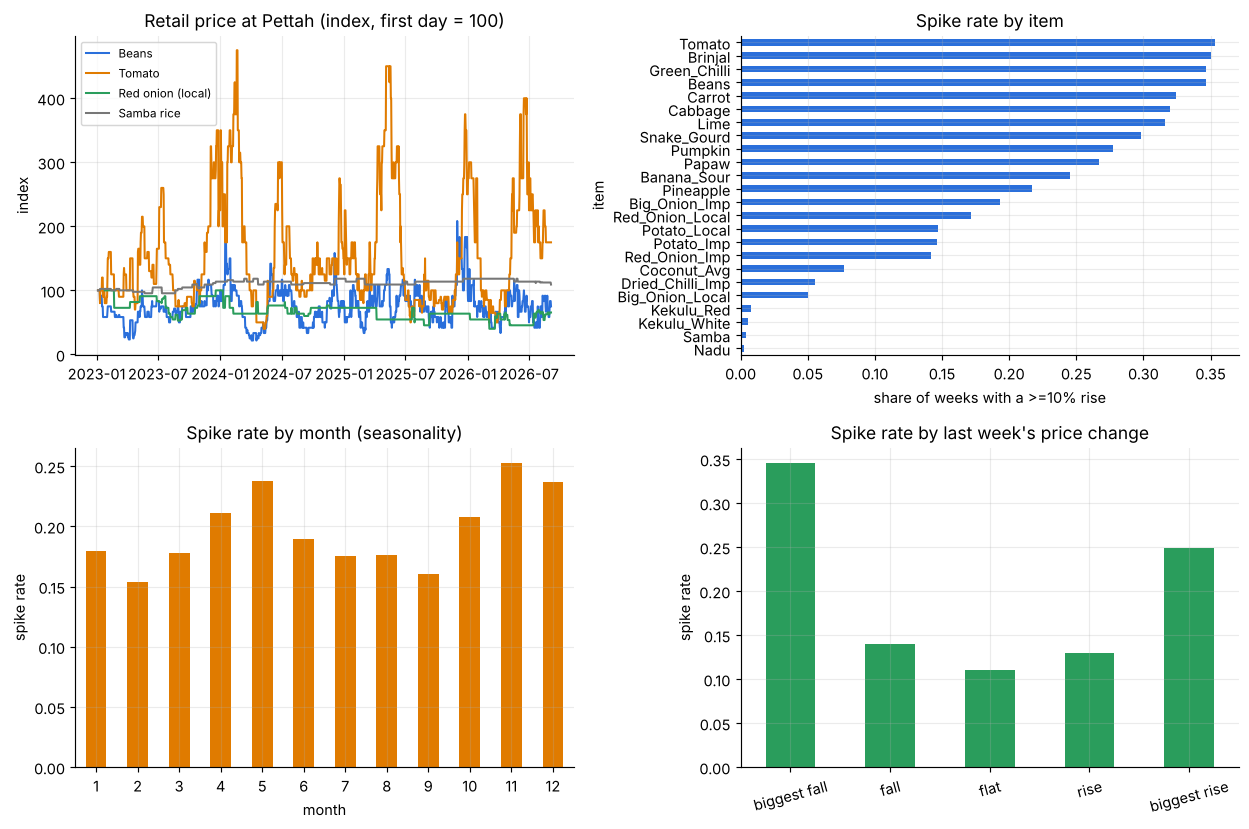

In [5]:
wide = raw.set_index("date")
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for it, col, c in [("Beans", "retail_pettah_Beans", BLUE), ("Tomato", "retail_pettah_Tomato", ORANGE),
                   ("Red onion (local)", "retail_pettah_Red_Onion_Local", GREEN), ("Samba rice", "retail_pettah_Samba", GREY)]:
    s = wide[col].dropna(); ax[0, 0].plot(s.index, s / s.iloc[0] * 100, label=it, color=c, lw=1.4)
ax[0, 0].set(title="Retail price at Pettah (index, first day = 100)", ylabel="index"); ax[0, 0].legend(fontsize=8)
L.groupby("item").spike.mean().sort_values().plot.barh(ax=ax[0, 1], color=BLUE); ax[0, 1].set(title="Spike rate by item", xlabel="share of weeks with a >=10% rise")
L.groupby("month").spike.mean().plot.bar(ax=ax[1, 0], color=ORANGE); ax[1, 0].set(title="Spike rate by month (seasonality)", ylabel="spike rate", xlabel="month"); ax[1, 0].tick_params(axis="x", rotation=0)
q = pd.qcut(F.r7.rank(method="first"), 5, labels=["biggest fall", "fall", "flat", "rise", "biggest rise"])
F.assign(spike=L.spike).groupby(q).spike.mean().plot.bar(ax=ax[1, 1], color=GREEN); ax[1, 1].set(title="Spike rate by last week's price change", ylabel="spike rate", xlabel=""); ax[1, 1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

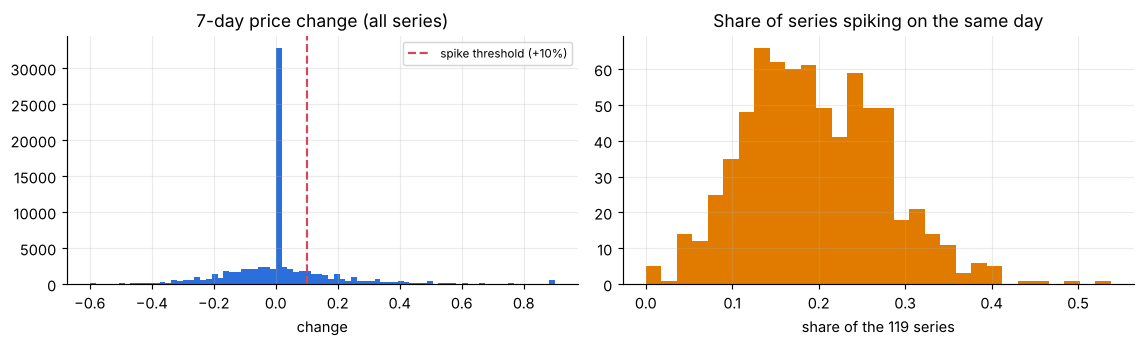

rainfall vs spike (correlation):  Nuwara Eliya 0.042 | Polonnaruwa 0.06
spike rate when last week's price was unchanged: 0.114 | overall: 0.195


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(L.change_7d.clip(-0.6, 0.9), bins=80, color=BLUE); ax[0].axvline(prep.SPIKE, color=RED, ls="--", label="spike threshold (+10%)"); ax[0].set(title="7-day price change (all series)", xlabel="change"); ax[0].legend(fontsize=8)
day = L.groupby("date").spike.mean(); ax[1].hist(day, bins=30, color=ORANGE); ax[1].set(title="Share of series spiking on the same day", xlabel="share of the 119 series")
plt.tight_layout(); plt.show()
print("rainfall vs spike (correlation):  Nuwara Eliya", round(np.corrcoef(L.spike, L.rain_ne_7d_mm)[0, 1], 3), "| Polonnaruwa", round(np.corrcoef(L.spike, L.rain_pol_7d_mm)[0, 1], 3))
print("spike rate when last week's price was unchanged:", round(F[F.r7 == 0].assign(s=L.spike[F.r7 == 0]).s.mean(), 3), "| overall:", round(L.spike.mean(), 3))

**What the EDA tells me**
- **Item matters enormously.** Perishables (tomato, brinjal, green chilli, beans) spike about 35% of weeks, whereas **rice varieties almost never do (under 1%)**. A pooled model can earn a good AUC just by "knowing" that rice is stable, so besides the pooled score I also report **within-item AUC** (can the model rank weeks inside one item?), the fairer measure.
- **The price signal is U-shaped.** After the biggest weekly *fall* the spike rate is ~35% (a rebound) and after the biggest *rise* ~25% (momentum), against 11 to 14% in between. A plain linear model cannot represent a U-shape in one raw variable, **but my features are log-ratios plus a 4-week volatility measure (`vol4`), and volatility captures most of that U-shape linearly**. So I expected trees to help; the results below show that, in this data, they only match logistic regression (see section 7).
- **Seasonality:** spikes are more common in November to December and May (monsoon and festival periods). Dambulla (the wholesale hub) spikes more than Narahenpita.
- **Rainfall is only weakly related** to spikes (correlation about 0.04 to 0.06): it is national, not per-crop, so expect it to be a minor feature.
- **Rows are not independent:** the 119 series move together on a given day, so the effective sample is closer to ~700 report days than to 85,000 rows. I therefore use date-block bootstrap for confidence intervals.

## 4. Existing approaches (baselines)
To justify a machine-learning model I compare it with what people would use without one, scored on the **validation year (2025)**:
- **Persistence** ("price stays the same"): never predicts a spike, so its AUC is 0.5 and its PR-AUC equals the spike rate.
- **Momentum rule** (last week's rise continues) and **mean-reversion rule** (a fall rebounds; also "price below its 4-week average").
- **ARIMA(7,1,0)** fitted per series (the classical time-series approach); its 7-day forecast is used as a spike score.
- **Logistic regression** (scaled features, one-hot categories): the standard linear classifier.

In [7]:
Fv = prep.add_features(val)
phis_val = arima.fit_params(raw, pd.Timestamp("2025-01-01"))          # ARIMA fitted on data before 2025 only
La = arima.add_arima_feature(L, raw, phis_val)
lr = models.make_model("LR", {"C": 1.0, "class_weight": "balanced"}).fit(train[prep.RAW_FEATURES], train.spike)
base = {
    "Persistence (no change)": {"AUC": 0.5, "PR_AUC": val.spike.mean()},
    "Momentum rule (+7-day change)": sc(val.spike, Fv.r7),
    "Mean-reversion rule (-7-day change)": sc(val.spike, -Fv.r7),
    "Below 4-week average rule": sc(val.spike, -Fv.gap4),
    "ARIMA(7,1,0) forecast": sc(val.spike, La.loc[val.index, "arima_fc7"]),
    "Logistic regression": sc(val.spike, lr.predict_proba(val[prep.RAW_FEATURES])[:, 1]),
}
pd.DataFrame(base).T.round(3).rename_axis("approach (validation 2025)")

,AUC,PR_AUC
approach (validation 2025),,
Persistence (no change),0.500,0.200
Momentum rule (+7-day change),0.447,0.214
Mean-reversion rule (-7-day change),0.553,0.288
Below 4-week average rule,0.568,0.298
"ARIMA(7,1,0) forecast",0.583,0.323
Logistic regression,0.761,0.408


## 5. Model selection and parameter engineering (no defaults)
**Why these models.** The data are tabular with mixed numeric and categorical features, non-linear (U-shaped) effects, and strong interactions (item × recent move). Tree ensembles suit this:
- **Random Forest** (bagging): many deep, decorrelated trees averaged. Robust, low tuning effort, reduces variance.
- **XGBoost** (boosting): shallow trees added one after another, each correcting the last. Reduces bias; strong regularisation controls.
- **LightGBM** (leaf-wise boosting): same idea, faster, with histogram binning; the `num_leaves` and `min_child_samples` controls matter.
- **CatBoost**: boosting with **native categorical handling** (ordered target statistics). `item`, `market` and `price_type` are genuine categories, so it is a natural fit.
- **Soft voting** averages probabilities (simple ensemble);
- **Stacking** (the third classic ensemble family): the four tuned models above are level-0 learners and a small logistic-regression *meta-learner* combines their probabilities. To avoid leakage, the meta-learner is trained only on **time-ordered out-of-fold predictions** (base models fitted on earlier years predict the next year), then the base models are refitted on all data; **ARIMA + RF** adds the ARIMA forecast as a feature (hybrid).

**Search design.** Randomised search with **time-ordered validation** (fit on 2023, validate on 2024; fit on 2023-24, validate on 2025). The score is the mean ROC-AUC over both folds (PR-AUC also recorded).
The 2026 test set is never used. Parameters searched (what each controls):

| Model | Parameters (range searched) |
|---|---|
| RF | `n_estimators` 200-400 · `max_depth` 6-20 · `min_samples_leaf` 10-200 (smoothness) · `max_features` sqrt/0.3/0.5 · `class_weight` balanced or none |
| XGBoost | `n_estimators` 200-600 · `learning_rate` 0.03-0.1 · `max_depth` 3-8 · `min_child_weight` 1-25 · `subsample`, `colsample_bytree` 0.6-1.0 · `reg_lambda` 1-10 |
| LightGBM | `n_estimators` 200-600 · `learning_rate` 0.03-0.1 · `num_leaves` 15-63 · `max_depth` · `min_child_samples` 20-200 · `subsample`, `colsample_bytree` · `reg_lambda` 0-10 |
| CatBoost | `iterations` 300-800 · `depth` 4-8 · `learning_rate` 0.03-0.1 · `l2_leaf_reg` 1-10 |

,candidates tried,library defaults: mean val AUC,best tuned: mean val AUC,best tuned: mean val PR-AUC
Random Forest,20,0.7401,0.7505,0.3883
XGBoost,30,0.7378,0.7611,0.4118
LightGBM,30,0.7552,0.7612,0.4089
CatBoost,12,0.7519,0.7624,0.4068


Random Forest  {'n_estimators': 400, 'max_depth': 8, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'class_weight': None}
XGBoost        {'n_estimators': 600, 'learning_rate': 0.05, 'max_depth': 3, 'min_child_weight': 5, 'subsample': 1.0, 'colsample_bytree': 0.8, 'reg_lambda': 5}
LightGBM       {'n_estimators': 200, 'learning_rate': 0.05, 'num_leaves': 63, 'max_depth': 6, 'min_child_samples': 50, 'subsample': 1.0, 'colsample_bytree': 0.6, 'reg_lambda': 10}
CatBoost       {'iterations': 300, 'depth': 4, 'learning_rate': 0.05, 'l2_leaf_reg': 10}


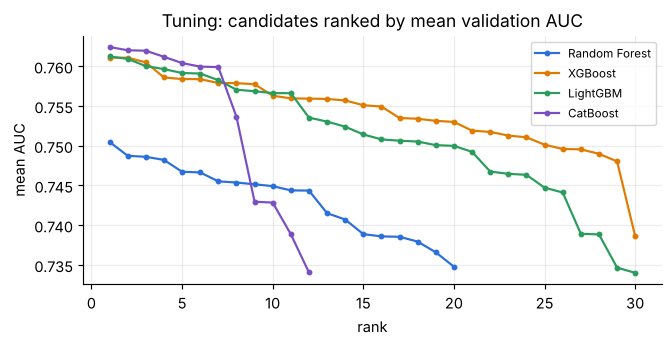

In [8]:
names = {"RF": "Random Forest", "XGB": "XGBoost", "LGBM": "LightGBM", "CAT": "CatBoost"}
tune = {n: pd.read_csv(f"results/tune_{n}.csv") for n in names}
dflt = pd.read_csv("results/tune_defaults.csv").set_index("model")
summary = pd.DataFrame({
    "candidates tried": {names[n]: len(t) for n, t in tune.items()},
    "library defaults: mean val AUC": {names[n]: dflt.loc[n, "mean_auc"] for n in names},
    "best tuned: mean val AUC": {names[n]: t.mean_auc.max() for n, t in tune.items()},
    "best tuned: mean val PR-AUC": {names[n]: t.loc[t.mean_auc.idxmax(), "mean_pr_auc"] for n, t in tune.items()},
}); display(summary.round(4))
best = {n: evaluate.load_best(n) for n in names}
for n in names: print(f"{names[n]:14s}", best[n])
fig, ax = plt.subplots(1, 1, figsize=(6.5, 3.4))
for (n, t), c in zip(tune.items(), [BLUE, ORANGE, GREEN, PURPLE]):
    ax.plot(range(1, len(t) + 1), t.mean_auc.sort_values(ascending=False).values, "o-", ms=3, color=c, label=names[n])
ax.set(title="Tuning: candidates ranked by mean validation AUC", xlabel="rank", ylabel="mean AUC"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading the tuning results**
- **Tuning helps, but modestly.** Tuned mean validation AUC beats the library defaults for every model (RF 0.740 to 0.751, XGBoost 0.738 to 0.761, LightGBM 0.755 to 0.761, CatBoost 0.752 to 0.762). The biggest gain is XGBoost, whose defaults (deep trees, little regularisation) overfit a noisy target.
- **The winners share a pattern: strong regularisation.** XGBoost chose depth 3 with 600 small steps; CatBoost chose depth 4 with `l2_leaf_reg`=10; LightGBM chose `reg_lambda`=10 and `min_child_samples`=50; RF chose `min_samples_leaf`=10 with only `sqrt` features. The target (a 10% rise next week) is noisy, so simple, smooth models generalise best. This is the bias-variance trade-off in practice.
- **The three boosters are within about 0.001 AUC of each other**, which is smaller than the noise between search candidates. Random search with 12 to 30 draws cannot separate them, so I do not claim any one is truly best from tuning alone. RF is lowest (bagging reduces variance but not bias, and the signal needs interactions).
- **Caveat:** 2025 is used both as the second tuning fold and as the validation year in section 6, so validation scores are slightly optimistic. That is why the final judgement uses the untouched 2026 test year.

## 6. Comparison on the validation year (2025)
Each tuned model is fitted on the training years and scored on 2025. The **decision threshold** (alert / no alert) is chosen here, by maximising F1 on the validation predictions, **before** the test set is touched.
(2025 also took part in tuning, so these numbers are slightly optimistic; the 2026 test in §7 is the unbiased check.)

In [9]:
val_prob = {}
for n in names:
    _, val_prob[names[n]] = evaluate.fit_predict(n, best[n], train, val)
_, val_prob["ARIMA + RF (hybrid)"] = evaluate.fit_predict("RF", best["RF"], La.loc[train.index], La.loc[val.index], hybrid=True)
val_prob["Soft vote (RF+XGB+LGBM+CAT)"] = np.mean([val_prob[names[n]] for n in names], axis=0)
_st = models.Stack(best).fit(train)   # time-ordered out-of-fold meta training
val_prob["Stacking (RF+XGB+LGBM+CAT, LR meta)"] = _st.predict_proba(val[prep.RAW_FEATURES])[:, 1]
print("stacking meta-learner weights (RF, XGB, LGBM, CAT):", _st.meta.coef_.round(2), "| out-of-fold rows:", _st.oof_rows)
thr = {k: evaluate.best_threshold(val.spike, p) for k, p in val_prob.items()}
vt = pd.DataFrame({k: evaluate.score_row(val.spike, p, thr[k]) for k, p in val_prob.items()}).T
display(vt[["AUC", "PR_AUC", "threshold", "accuracy", "bal_acc", "recall", "precision", "F1"]].round(3).rename_axis("validation 2025"))

stacking meta-learner weights (RF, XGB, LGBM, CAT): [[ 0.25  0.58 -0.29  0.41]] | out-of-fold rows: 22372


,AUC,PR_AUC,threshold,accuracy,bal_acc,recall,precision,F1
validation 2025,,,,,,,,
Random Forest,0.766,0.417,0.239,0.678,0.694,0.721,0.352,0.473
XGBoost,0.768,0.423,0.180,0.629,0.697,0.810,0.327,0.466
LightGBM,0.773,0.424,0.204,0.660,0.700,0.767,0.343,0.474
CatBoost,0.771,0.420,0.211,0.669,0.698,0.746,0.348,0.475
ARIMA + RF (hybrid),0.775,0.434,0.243,0.699,0.699,0.698,0.368,0.482
Soft vote (RF+XGB+LGBM+CAT),0.776,0.434,0.208,0.658,0.704,0.781,0.344,0.478
"Stacking (RF+XGB+LGBM+CAT, LR meta)",0.773,0.430,0.218,0.640,0.702,0.805,0.335,0.473


In [10]:
single = [names[n] for n in names]
FINAL_NAME = max(single, key=lambda k: roc_auc_score(val.spike, val_prob[k]) + average_precision_score(val.spike, val_prob[k]))
FINAL_KEY = [k for k, v in names.items() if v == FINAL_NAME][0]
print("Selected single model (best validation AUC + PR-AUC):", FINAL_NAME, best[FINAL_KEY])

Selected single model (best validation AUC + PR-AUC): LightGBM {'n_estimators': 200, 'learning_rate': 0.05, 'num_leaves': 63, 'max_depth': 6, 'min_child_samples': 50, 'subsample': 1.0, 'colsample_bytree': 0.6, 'reg_lambda': 10}


## 7. Final evaluation on the untouched test year (2026)
All models are refitted on **train + validation (2023-25)** with the locked parameters, then scored once on 2026 using the validation-chosen thresholds. ARIMA is refitted on data before 2026.

In [11]:
trval = pd.concat([train, val])
phis_te = arima.fit_params(raw, pd.Timestamp("2026-01-01")); La2 = arima.add_arima_feature(L, raw, phis_te)
final, test_prob = {}, {}
for n in names:
    final[names[n]], test_prob[names[n]] = evaluate.fit_predict(n, best[n], trval, test)
_, test_prob["ARIMA + RF (hybrid)"] = evaluate.fit_predict("RF", best["RF"], La2.loc[trval.index], La2.loc[test.index], hybrid=True)
test_prob["Soft vote (RF+XGB+LGBM+CAT)"] = np.mean([test_prob[names[n]] for n in names], axis=0)
test_prob["Stacking (RF+XGB+LGBM+CAT, LR meta)"] = models.Stack(best).fit(trval).predict_proba(test[prep.RAW_FEATURES])[:, 1]
Ft = prep.add_features(test)
lr2 = models.make_model("LR", {"C": 1.0, "class_weight": "balanced"}).fit(trval[prep.RAW_FEATURES], trval.spike)
test_prob["Logistic regression"] = lr2.predict_proba(test[prep.RAW_FEATURES])[:, 1]
test_prob["ARIMA(7,1,0) alone"] = La2.loc[test.index, "arima_fc7"].values
test_prob["Mean-reversion rule"] = -Ft.r7.values
rows = {}
for k, p in test_prob.items():
    rows[k] = evaluate.score_row(test.spike, p, thr.get(k))
tt = pd.DataFrame(rows).T
print(f"test rows: {len(test):,} | report days: {test.date.nunique()} | spike rate: {test.spike.mean():.3f}")
display(tt[["AUC", "PR_AUC", "threshold", "accuracy", "bal_acc", "recall", "precision", "F1"]].round(3).rename_axis("TEST 2026"))

test rows: 17,969 | report days: 151 | spike rate: 0.189


,AUC,PR_AUC,threshold,accuracy,bal_acc,recall,precision,F1
TEST 2026,,,,,,,,
Random Forest,0.754,0.387,0.239,0.684,0.678,0.667,0.332,0.444
XGBoost,0.770,0.407,0.180,0.618,0.703,0.839,0.310,0.453
LightGBM,0.771,0.410,0.204,0.646,0.698,0.781,0.320,0.454
CatBoost,0.762,0.372,0.211,0.653,0.696,0.765,0.322,0.454
ARIMA + RF (hybrid),0.766,0.421,0.243,0.706,0.683,0.646,0.349,0.453
Soft vote (RF+XGB+LGBM+CAT),0.770,0.404,0.208,0.646,0.701,0.789,0.321,0.456
"Stacking (RF+XGB+LGBM+CAT, LR meta)",0.769,0.400,0.218,0.646,0.699,0.783,0.321,0.455
Logistic regression,0.771,0.408,NaN,NaN,NaN,NaN,NaN,NaN
"ARIMA(7,1,0) alone",0.625,0.349,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
order = [FINAL_NAME] + [k for k in ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "Soft vote (RF+XGB+LGBM+CAT)", "Stacking (RF+XGB+LGBM+CAT, LR meta)", "ARIMA + RF (hybrid)", "Logistic regression", "ARIMA(7,1,0) alone", "Mean-reversion rule"] if k != FINAL_NAME]
ci, diff = evaluate.date_bootstrap(test.spike, {k: test_prob[k] for k in order}, test.date.values, n_boot=300)
out = pd.DataFrame({"AUC": [tt.loc[k, "AUC"] for k in order], "95% CI (by report day)": [f"{ci[k][0]:.3f} to {ci[k][1]:.3f}" for k in order],
                    f"AUC difference vs {FINAL_NAME}": ["-"] + [f"{diff[k][0]:+.3f} to {diff[k][1]:+.3f}" for k in order[1:]]}, index=order)
display(out)

,AUC,95% CI (by report day),AUC difference vs LightGBM
LightGBM,0.771395,0.759 to 0.784,-
Random Forest,0.753637,0.742 to 0.765,-0.024 to -0.011
XGBoost,0.770239,0.759 to 0.783,-0.004 to +0.002
CatBoost,0.761913,0.750 to 0.774,-0.014 to -0.005
Soft vote (RF+XGB+LGBM+CAT),0.769728,0.758 to 0.782,-0.004 to +0.001
"Stacking (RF+XGB+LGBM+CAT, LR meta)",0.768565,0.757 to 0.780,-0.006 to +0.000
ARIMA + RF (hybrid),0.766376,0.756 to 0.776,-0.013 to +0.002
Logistic regression,0.771124,0.759 to 0.782,-0.007 to +0.006
"ARIMA(7,1,0) alone",0.624621,0.604 to 0.643,-0.171 to -0.125
Mean-reversion rule,0.578373,0.560 to 0.602,-0.215 to -0.169


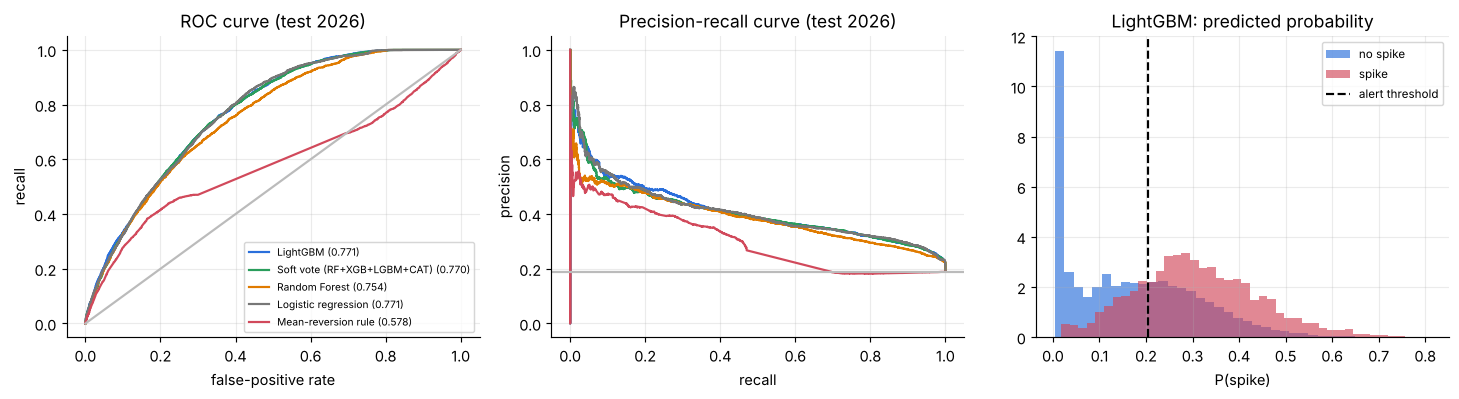

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.9))
show = {FINAL_NAME: BLUE, "Soft vote (RF+XGB+LGBM+CAT)": GREEN, "Random Forest": ORANGE, "Logistic regression": GREY, "Mean-reversion rule": RED}
for k, c in show.items():
    f_, t_, _ = roc_curve(test.spike, test_prob[k]); ax[0].plot(f_, t_, color=c, label=f"{k} ({tt.loc[k,'AUC']:.3f})")
    p_, r_, _ = precision_recall_curve(test.spike, test_prob[k]); ax[1].plot(r_, p_, color=c, label=k)
ax[0].plot([0, 1], [0, 1], color="#bbb"); ax[0].set(title="ROC curve (test 2026)", xlabel="false-positive rate", ylabel="recall"); ax[0].legend(fontsize=7)
ax[1].axhline(test.spike.mean(), color="#bbb"); ax[1].set(title="Precision-recall curve (test 2026)", xlabel="recall", ylabel="precision")
pf = test_prob[FINAL_NAME]; h = ax[2]
h.hist(pf[test.spike == 0], bins=40, alpha=.65, color=BLUE, label="no spike", density=True); h.hist(pf[test.spike == 1], bins=40, alpha=.65, color=RED, label="spike", density=True)
h.axvline(thr[FINAL_NAME], color="k", ls="--", label="alert threshold"); h.set(title=f"{FINAL_NAME}: predicted probability", xlabel="P(spike)"); h.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Is the model good *within* an item, or just recognising stable items?
The pooled AUC mixes two skills: telling items apart (rice vs tomato) and ranking *weeks* inside an item. The second is what an early-warning user needs.

pooled AUC (all items): 0.771
pooled AUC (volatile items only, excl. 5 stable staples): 0.707
mean within-item AUC over 19 items: 0.649   (mean-reversion rule: 0.588)


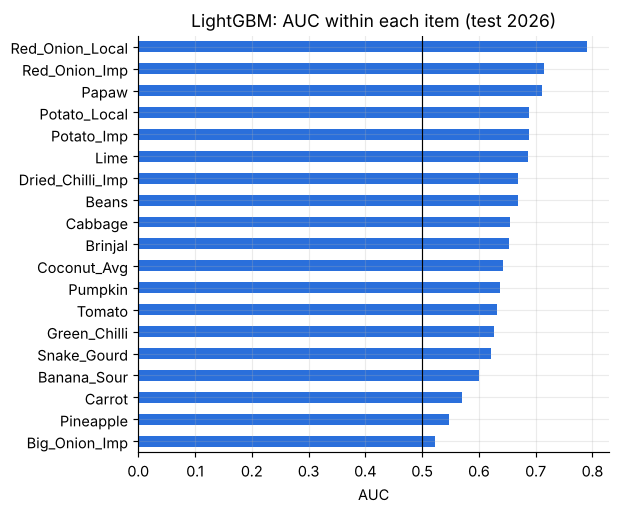

if only the top 10% of weekly scores raise an alert: precision = 48.2% (base rate 18.9%), catches 25.6% of spikes


In [14]:
def within_item_auc(df, p, min_n=20):
    out = {}
    for it, g in df.assign(p=p).groupby("item"):
        if g.spike.sum() >= min_n and (g.spike == 0).sum() >= min_n:
            out[it] = roc_auc_score(g.spike, g.p)
    return pd.Series(out).sort_values()
pf = test_prob[FINAL_NAME]
wi = within_item_auc(test, pf); wi_rule = within_item_auc(test, test_prob["Mean-reversion rule"])
trate = train.groupby("item").spike.mean(); veg = trate[trate >= 0.05].index
m = test.item.isin(veg).values
print(f"pooled AUC (all items): {roc_auc_score(test.spike, pf):.3f}")
print(f"pooled AUC (volatile items only, excl. {len(trate) - len(veg)} stable staples): {roc_auc_score(test.spike[m], pf[m]):.3f}")
print(f"mean within-item AUC over {len(wi)} items: {wi.mean():.3f}   (mean-reversion rule: {wi_rule.mean():.3f})")
fig, ax = plt.subplots(figsize=(6, 5)); wi.plot.barh(ax=ax, color=BLUE); ax.axvline(0.5, color="k", lw=.8); ax.set(title=f"{FINAL_NAME}: AUC within each item (test 2026)", xlabel="AUC"); plt.tight_layout(); plt.show()
thr10 = np.quantile(pf, 0.9); top = pf >= thr10
print(f"if only the top 10% of weekly scores raise an alert: precision = {test.spike[top].mean():.1%} (base rate {test.spike.mean():.1%}), catches {test.spike[top].sum() / test.spike.sum():.1%} of spikes")

**Reading the test results (2026, never used for fitting, tuning or thresholds)**
1. **Boosted trees do not beat logistic regression.** LightGBM, XGBoost, the soft vote and logistic regression all score AUC ~0.77, and every pairwise confidence interval for the difference includes zero. The only models significantly worse than LightGBM are Random Forest (-0.024 to -0.011), CatBoost (-0.014 to -0.005), ARIMA alone and the simple rules. **I selected LightGBM because it won on validation (the rule I fixed in advance), not because it is demonstrably better than a linear model.** Logistic regression is a defensible, simpler alternative.
2. **Stacking (0.769) does not beat its own members either.** The logistic-regression meta-learner (trained on time-ordered out-of-fold predictions) gave weights RF 0.25, XGBoost 0.58, LightGBM -0.29, CatBoost 0.41; the negative LightGBM weight is a sign that the four boosters are highly correlated, so there is little new information to combine. Bagging, boosting, voting and stacking all land within about 0.005 AUC of each other: on this data the ceiling is set by the information in the features, not by the model family.
3. **ARIMA alone is weak (AUC 0.625), but the ARIMA + RF hybrid (0.766) beats plain RF (0.754).** The ARIMA forecast adds information that RF cannot easily build from raw lags. The hybrid still does not beat the boosters, and it needs a per-series ARIMA fit, so it cannot be run from the app's raw inputs; it is evaluated here only.
4. **Machine learning clearly beats the existing approaches** (persistence 0.50, momentum 0.45, mean-reversion 0.58, ARIMA 0.63) by a wide margin.
5. **How much of 0.77 is real skill?** Much of it is item identity. Supplementary check (`src/extra_checks.py`, test year):

| Scorer | pooled AUC | volatile-items AUC | within-item AUC |
|---|---|---|---|
| Item base rate only (no price info) | 0.723 | 0.642 | 0.500 |
| Series base rate only (item x market x type) | 0.737 | 0.660 | 0.578 |
| 4-week volatility (`vol4`) alone | 0.712 | 0.636 | 0.544 |
| LightGBM (selected) | 0.771 | 0.707 | 0.649 |
| XGBoost | 0.770 | 0.705 | 0.652 |
| Logistic regression | 0.771 | 0.708 | 0.666 |

   A lookup of each item's historic spike rate already gets 0.723. The models add about 0.05 pooled and about 0.15 within items over that. Within items, logistic regression (0.666) is slightly but significantly better than LightGBM (0.649): date-block bootstrap of the difference gives -0.016 (95% CI -0.029 to -0.004).
6. **Practical meaning.** At the validation-chosen threshold the alert catches about 78% of spikes but only ~32% of alerts are real (base rate 19%), so it is a screening tool, not a forecast. If only the top 10% of weekly scores raise an alert, precision rises to 48% (catching 26% of spikes).

**Note on the model choice.** Given the table above, the deployed LightGBM is not demonstrably better than logistic regression on the test year. I kept LightGBM because the selection rule (best validation AUC + PR-AUC) was fixed before the test year was opened, and changing the choice after seeing test results would be test-set selection. The comparison is reported openly, and `python src/train_final.py LGBM` can be swapped for any other model in one command.

## 8. Interpretation with SHAP and LIME
Both methods explain the **selected model** (refitted on 2023-25). **SHAP** gives each feature's additive contribution (in log-odds) to every prediction, which also yields a global ranking.
**LIME** fits a small local linear model around one prediction by perturbing its inputs. The one-hot columns of `item`, `market` and `price_type` are summed back so each original feature has one SHAP value.

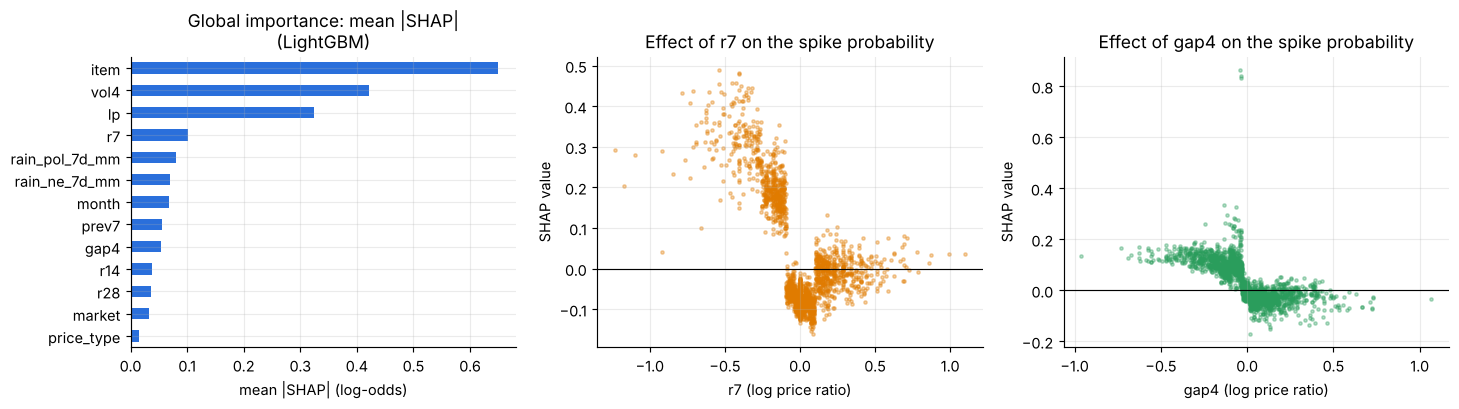

share of total |SHAP| by feature:


,item,vol4,lp,r7,rain_pol_7d_mm,rain_ne_7d_mm,month,prev7,gap4,r14,r28,market,price_type
share,0.334,0.217,0.167,0.052,0.041,0.036,0.035,0.028,0.028,0.019,0.018,0.017,0.007


In [15]:
pipe = final[FINAL_NAME]
samp = test.sample(3000, random_state=0)
agg, Xs, base_val = explain.shap_by_feature(pipe, samp[prep.RAW_FEATURES])
imp = agg.abs().mean().sort_values()
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
imp.plot.barh(ax=ax[0], color=BLUE); ax[0].set(title=f"Global importance: mean |SHAP|\n({FINAL_NAME})", xlabel="mean |SHAP| (log-odds)")
for a, f, c in [(ax[1], "r7", ORANGE), (ax[2], "gap4", GREEN)]:
    a.scatter(Xs[f], agg[f], s=5, alpha=.35, color=c); a.axhline(0, color="k", lw=.8)
    a.set(title=f"Effect of {f} on the spike probability", xlabel=f"{f} (log price ratio)", ylabel="SHAP value")
plt.tight_layout(); plt.show()
print("share of total |SHAP| by feature:"); display((imp[::-1] / imp.sum()).round(3).to_frame("share").T)

**Local explanation of one prediction.** Take a real test case that the model flagged strongly and that did spike, and explain it twice (SHAP, LIME).

      date  item market price_type  price_now  price_7d_ago  price_14d_ago  price_28d_ago  rain_ne_7d_mm  rain_pol_7d_mm
2026-01-09 Beans pettah  wholesale      400.0         400.0         1000.0          800.0           41.8            96.7
model P(spike) = 0.667 | actual 7-day change = +50.0%


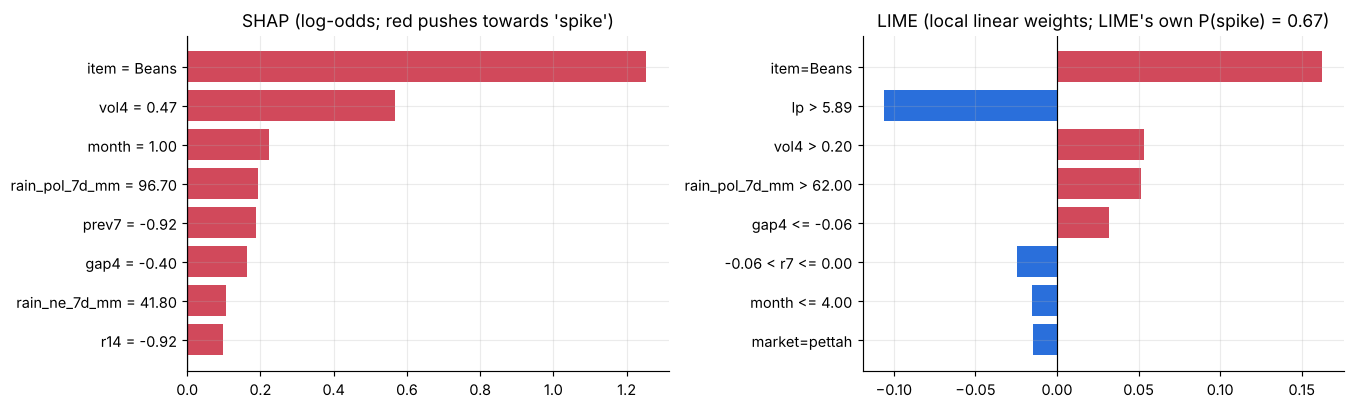

In [16]:
cand = test[(test.spike == 1) & (test.item.isin(["Beans", "Tomato", "Green_Chilli", "Brinjal", "Carrot"]))].copy()
cand["p"] = pipe.predict_proba(cand[prep.RAW_FEATURES])[:, 1]
case = cand.sort_values("p", ascending=False).iloc[[20]]                 # a clear but not extreme case
row = case[prep.RAW_FEATURES]
print(case[["date", "item", "market", "price_type", "price_now", "price_7d_ago", "price_14d_ago", "price_28d_ago", "rain_ne_7d_mm", "rain_pol_7d_mm"]].to_string(index=False))
print(f"model P(spike) = {case.p.iloc[0]:.3f} | actual 7-day change = {case.change_7d.iloc[0]:+.1%}")
a1, X1, b1 = explain.shap_by_feature(pipe, row)
s1 = a1.iloc[0].sort_values(key=abs).tail(8)
helper = explain.LimeHelper(pipe, trval.sample(6000, random_state=0)); exp = helper.explain(row, num_features=8)
lime_list = sorted(exp.as_list(), key=lambda t: abs(t[1]))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh([f"{k} = {X1[k].iloc[0]:.2f}" if k not in prep.CATEGORICAL else f"{k} = {X1[k].iloc[0]}" for k in s1.index], s1.values, color=[RED if v > 0 else BLUE for v in s1.values]); ax[0].set(title="SHAP (log-odds; red pushes towards 'spike')"); ax[0].axvline(0, color="k", lw=.8)
ax[1].barh([t[0] for t in lime_list], [t[1] for t in lime_list], color=[RED if t[1] > 0 else BLUE for t in lime_list]); ax[1].set(title=f"LIME (local linear weights; LIME's own P(spike) = {exp.predict_proba[1]:.2f})"); ax[1].axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()

**Reading SHAP and LIME**
- **Global (SHAP).** `item` (33% of total |SHAP|), `vol4` (22%) and `lp`, the log price level (17%), dominate. Recent changes (`r7`, `prev7`, `gap4`, `r14`, `r28`) are individually small. **Rainfall (about 4% each) and month (3.5%) are minor**, in line with the weak correlations in the EDA, so the "weather drives prices" story is only weakly supported here. `item` being the top feature agrees with the item-identity finding in section 7: much of what the model "knows" is which vegetables are volatile.
- **Direction.** Read the direction from the beeswarm plot above (colour = feature value, position = push up or down); I do not restate it from memory here.
- **Local (SHAP vs LIME).** For the flagged Beans (Pettah, wholesale) case, where price had fallen from 1000 to 400 before the spike, compare the two bar charts above: features that appear in both (the price history and volatility features) are the reliable story, and features that appear in only one are LIME noise or SHAP detail. SHAP gives exact additive contributions for the tree model (base value + contributions = prediction); LIME fits a local linear surrogate around perturbed points, so its weights are approximate and can change with the random seed. Agreement between two different methods is the reassurance; where they disagree on small features, I trust SHAP more for tree models.
- **Caveat.** Both describe what the model uses, not what causes price spikes.

## 9. Strengths, limitations and justification
**Why this approach is effective**
- Time-ordered splits with whole target windows inside each split, so no future information leaks; the test year is touched once.
- Real reports only (733 of 1,339 daily rows), because the file's `is_interpolated` flag is wrong and duplicated rows would otherwise inflate samples.
- Features are scale-free (log-ratios, volatility) so one model works across items priced from Rs 50 to Rs 1,000+.
- Heavy regularisation chosen by tuning, matching a noisy target.

**Models compared**

| Model | Strengths | Limitations (here) |
|---|---|---|
| Logistic regression | Simple, fast, interpretable; **best within-item AUC (0.666)** | Cannot learn interactions on its own |
| Random Forest | Robust, little tuning | Significantly worse on test (0.754); bagging does not reduce bias |
| XGBoost | Strong, well regularised after tuning | Matches but does not beat LR; needs careful tuning |
| LightGBM (**deployed**) | Fast, best validation score | Ties LR/XGBoost on test; slightly worse than LR within items |
| CatBoost | Native categoricals, strong with defaults | Significantly worse than LightGBM on test (0.762) |
| Soft vote | Smooths model noise | No gain over its best member; four models to maintain |
| Stacking (LR meta) | The classic third ensemble family; learns how to weight models | 0.769 test AUC: no gain, boosters too correlated; needs time-ordered out-of-fold training |
| ARIMA alone | The classic time-series baseline | Weak (0.625): univariate, ignores item and market context |
| ARIMA + RF | Beats plain RF | Cannot be deployed from simple user inputs; no gain over boosters |

**Honest limitations**
1. **Only ~3 years and ~700 report days**; rows within a day are strongly correlated, so confidence is lower than 85,000 rows suggest.
2. **Item identity drives much of the pooled AUC** (item base rate alone: 0.723). Within-item skill is modest (about 0.65).
3. **Low precision** (~32% at the chosen threshold); useful for ranking and screening only.
4. **Validation 2025 was used for tuning and model choice**, so its scores are optimistic; thresholds come from train-only models but are applied to train+val refits.
5. **Rainfall is only two national stations**, not crop-growing regions; the data have no fuel, transport or import information, which likely matter most for price shocks.
6. **Licence of the dataset is not stated**; prices come from public CBSL reports and rainfall from Open-Meteo. Both are cited.
7. **Model choice:** LightGBM was selected by validation; a simpler logistic regression would be an equally defensible deployment.

## 9b. Group checks (bias and fairness) and partial dependence
The brief asks about risks of bias or unfairness and whether the model agrees with domain knowledge. Here the data hold no personal information, so "fairness" means: **does the alert work equally well for every market, price type and item group?** I score the deployed model on the 2026 test year by group, and draw partial-dependence (PDP) curves of the three strongest numeric features.

market


,rows,spike rate,alert rate,recall,precision,AUC
market,,,,,,
dambulla,7248.0,0.231,0.565,0.851,0.348,0.766
narahenpita,3624.0,0.144,0.262,0.498,0.274,0.745
pettah,7097.0,0.168,0.454,0.808,0.299,0.778


price_type


,rows,spike rate,alert rate,recall,precision,AUC
price_type,,,,,,
retail,10872.0,0.178,0.412,0.718,0.310,0.763
wholesale,7097.0,0.205,0.533,0.866,0.333,0.781


item_group


,rows,spike rate,alert rate,recall,precision,AUC
item_group,,,,,,
stable staples (rice etc.),3775.0,0.018,0.001,0.000,0.00,0.921
volatile items,14194.0,0.234,0.582,0.797,0.32,0.707


,rows,spike rate,alert rate,recall,precision,AUC
item,,,,,,
Tomato,755.0,0.371,0.815,0.918,0.418,0.632
Brinjal,755.0,0.344,0.861,0.938,0.375,0.653
Green_Chilli,755.0,0.336,0.807,0.866,0.361,0.626
Lime,755.0,0.331,0.853,0.904,0.351,0.687
Beans,755.0,0.325,0.781,0.886,0.368,0.669
Carrot,755.0,0.295,0.882,0.924,0.309,0.570
Snake_Gourd,755.0,0.289,0.803,0.908,0.327,0.622
Pumpkin,755.0,0.277,0.838,0.914,0.302,0.638


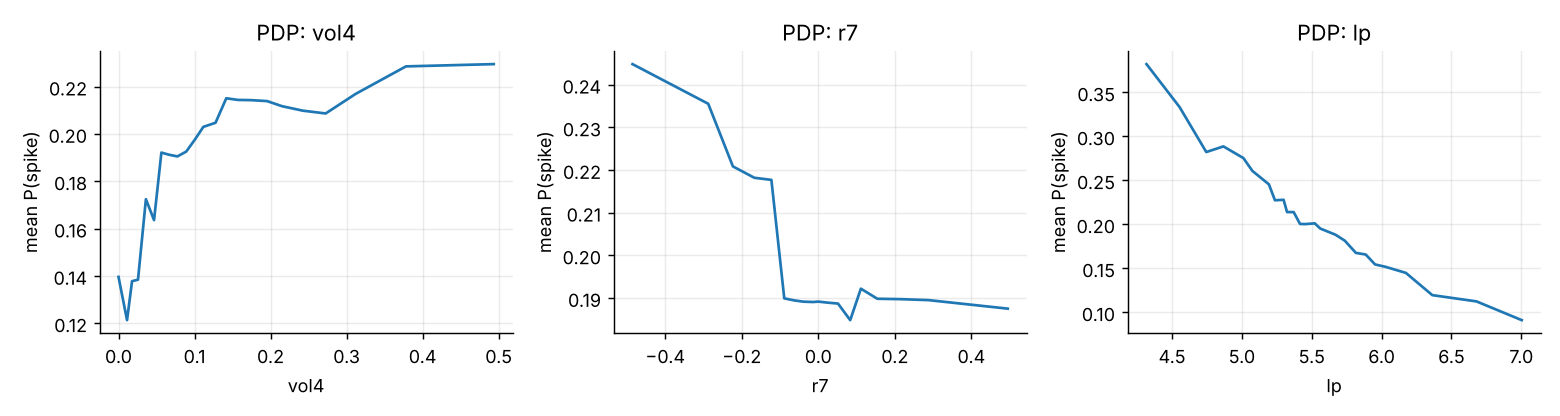

In [17]:
import fairness
from IPython.display import Image
res, per_item = fairness.main()
for k, v in res.items():
    print(k); display(v.round(3))
display(per_item.round(3).head(8))
display(Image(filename="results/pdp.png"))

**What the group checks show**
- **Markets are not served equally.** Narahenpita (retail only, 14% spike rate) gets far fewer alerts (26% of weeks) and the model catches only **50% of its spikes**, against 85% in Dambulla and 81% in Pettah. Narahenpita buyers would be warned less often when prices do jump. AUC is similar across markets (0.75 to 0.78), so this is a threshold/calibration effect: one threshold is applied to all markets. A per-market threshold would be the fix.
- **Retail is under-served relative to wholesale:** recall 0.72 vs 0.87.
- **The alert fires too often for the volatile items.** For tomato, brinjal, green chilli, lime, beans and carrot the alert fires in 78% to 88% of weeks while only 30% to 37% of those weeks spike, and within-item AUC is just 0.57 to 0.69. For these items an alert says "this is a volatile vegetable" more than "this week is special". The app therefore shows each item's usual spike rate beside the probability.
- **Stable staples (rice varieties)** almost never spike (under 2%); the model correctly raises almost no alerts there. Their pooled AUC (0.92) is high but not meaningful, because there are hardly any spikes to rank.
- **Domain check (PDP).** Spike probability rises with recent volatility (`vol4`) and then levels off above about 0.15. It is higher after a sharp fall in last week's price (`r7` below about -0.1, a rebound) and flat after rises, so the PDP shows **mean reversion but not a momentum effect** (the U-shape in the raw EDA is mostly carried by volatility). It falls steadily with price level (`lp`): cheap, abundant items spike more often than expensive ones. This agrees with how perishable-vegetable markets behave (gluts push prices down and then they rebound; volatile cheap items swing most), but I treat it as consistency with domain knowledge, not as proof of cause.

## 10. Single-sample inference and pickle export
The deployed object is **one pipeline** that starts from the 10 raw inputs a user can type (item, market, price type, four prices, two rainfall totals, month) and returns a probability; the pickle also stores the alert threshold and metadata.

In [18]:
keep = [FINAL_NAME] + [k for k in ["Random Forest", "XGBoost", "LightGBM", "CatBoost", "Soft vote (RF+XGB+LGBM+CAT)", "Stacking (RF+XGB+LGBM+CAT, LR meta)", "ARIMA + RF (hybrid)", "Logistic regression", "Mean-reversion rule"] if k != FINAL_NAME]
report = tt[["AUC", "PR_AUC", "recall", "precision", "F1"]].loc[keep]
bundle, path = export.save_bundle(final[FINAL_NAME], FINAL_NAME, best[FINAL_KEY], thr[FINAL_NAME], L, report=report.round(4).to_dict(orient="index"), importance=imp.round(5).to_dict(), path="model.pkl")
import os; print("saved", path, f"({os.path.getsize(path) / 1e6:.1f} MB)")

# --- reload from disk; predict ONE raw sample exactly as the app does
with open("model.pkl", "rb") as f: b = pickle.load(f)
one = test[(test.item == "Tomato") & (test.market == "dambulla") & (test.price_type == "retail")].iloc[[40]]
sample = one[b["raw_features"]].iloc[0].to_dict(); print("raw inputs:", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in sample.items()})
p1 = b["pipeline"].predict_proba(pd.DataFrame([sample]))[0, 1]
print(f"P(price rises >=10% within 7 days) = {p1:.3f} | alert threshold = {b['threshold']:.3f} ->", "ALERT" if p1 >= b["threshold"] else "no alert", f"| actual 7-day change: {one.change_7d.iloc[0]:+.1%}")
chk = test.iloc[:500]; print("reloaded model reproduces in-memory predictions:", np.allclose(b["pipeline"].predict_proba(chk[b["raw_features"]])[:, 1], final[FINAL_NAME].predict_proba(chk[prep.RAW_FEATURES])[:, 1]))

saved model.pkl (0.8 MB)
raw inputs: {'item': 'Tomato', 'market': 'dambulla', 'price_type': 'retail', 'price_now': 90.0, 'price_7d_ago': 140.0, 'price_14d_ago': 150.0, 'price_28d_ago': 130.0, 'rain_ne_7d_mm': 10.4, 'rain_pol_7d_mm': 2.8, 'month': 3}
P(price rises >=10% within 7 days) = 0.467 | alert threshold = 0.204 -> ALERT | actual 7-day change: +11.1%
reloaded model reproduces in-memory predictions: True


**Pickle caveats.** The pickle stores *references* to my custom code (`prep.add_features`), so `src/` must be importable and library versions should match (`requirements.txt`). Never unpickle files from untrusted sources.

## 11. Front end and MLOps
- **`app.py`** (Streamlit; generated with GenAI prompts recorded in the README) loads `model.pkl`. The user picks an item, market and price type; the boxes are pre-filled with the latest real prices, can be edited, and the app returns the spike probability and an alert. A second tab shows the held-out test results and the SHAP importance. Run: `streamlit run app.py`.
- **MLOps (bonus).** The source dataset is refreshed daily by a GitHub Action. `python src/train_final.py` rebuilds the dataset features, refits the chosen model with the saved parameters, evaluates it on the newest period and rewrites `model.pkl`, so retraining is a single command. Monitoring idea: track the rolling AUC of recent weeks and retrain when it falls below the validation level.

## 12. Reproducibility and references
Fixed seeds (`random_state=42`); the search is re-runnable with `python src/tune.py RF|XGB|LGBM|CAT`; versions in `requirements.txt`.
Data: CBSL Daily Price Reports (via *Srilanka-vegetable-prices*, Hugging Face) and Open-Meteo rainfall. References: Breiman (2001) Random Forests; Chen and Guestrin (2016) XGBoost; Ke et al. (2017) LightGBM; Prokhorenkova et al. (2018) CatBoost; Lundberg and Lee (2017) SHAP; Ribeiro et al. (2016) LIME; Box and Jenkins ARIMA.